# Impact des data centers : croisement avec des sources externes (points 7 à 11)
Prérequis : `pip install pandas numpy matplotlib folium` · `export_summary.csv` dans le même dossier.
Toutes les données externes sont rassemblées dans **un seul tableau** (cellule 0) avec leur source, leur année et leur périmètre, pour pouvoir les citer et les mettre à jour.

## 0. Chargement, style et tableau des données externes (à exécuter en premier)

In [ ]:
import os, json, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.patches import Patch, Rectangle

VERT, ORANGE, GRIS, ENCRE, BLEU, ANTHRA = "#1f7a6d", "#e08a2e", "#8f8f89", "#1d1d1b", "#4a6fa5", "#55554f"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 11, "text.color": ENCRE,
                     "axes.labelcolor": ENCRE, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left"})
os.makedirs("figures", exist_ok=True)
fmt = lambda v, d=0: f"{v:,.{d}f}".replace(",", " ").replace(".", ",")      # 1 400 ; 7,4

# --- Tes données (France) ---
df = pd.read_csv("export_summary.csv")
df = df[df["country"] == "France"].copy()
df["statut"] = np.where(df["progress_step"] == "operating", "En service", "En projet")
df["mw"] = df["power_total_mw"].replace(0, np.nan)               # 0 MW = valeur manquante
GW_SERVICE = df.loc[df.statut == "En service", "mw"].sum() / 1000
GW_PROJET = df.loc[df.statut == "En projet", "mw"].sum() / 1000
N_PROJ_SANS_MW = int(((df.statut == "En projet") & df.mw.isna()).sum())
print(f"Tes données : {GW_SERVICE:.2f} GW en service ; {GW_PROJET:.2f} GW en projet "
      f"({N_PROJ_SANS_MW} projets sans puissance : le chiffre est donc un minimum)")

# --- Données externes : une ligne = une valeur sourcée ---
EXT = pd.DataFrame([
 # indicateur, valeur_basse, valeur_haute, unité, année, périmètre / remarque, source
 ("Conso. data centers, sites dédiés", 4, 5, "TWh", 2024, "RTE, sites dédiés, hors salles internes", "RTE, Bilan prévisionnel 2025 (déc. 2025)"),
 ("Conso. data centers, sites dédiés", 10, 15, "TWh", 2030, "10 si 30 % des projets aboutissent, 15 si 60 %", "RTE, Bilan prévisionnel 2025"),
 ("Conso. data centers, sites dédiés", 21, 32, "TWh", 2035, "selon les 2 trajectoires de décarbonation", "RTE, Bilan prévisionnel 2025"),
 ("Conso. data centers, périmètre large", 10, 10, "TWh", 2026, "≈ 2 % de la consommation, inclut les salles internes", "RTE (page grand public)"),
 ("Conso. data centers, périmètre large", 23, 28, "TWh", 2035, "périmètre large RTE", "RTE (page grand public)"),
 ("Consommation électrique France", 451, 451, "TWh", 2025, "consommation totale", "RTE, Bilan électrique 2025"),
 ("Consommation électrique France", 470, 510, "TWh", 2030, "trajectoire lente (470) / rapide (510)", "RTE, Bilan prévisionnel 2025"),
 ("Consommation électrique France", 505, 580, "TWh", 2035, "trajectoire lente (505) / rapide (580)", "RTE, Bilan prévisionnel 2025"),
 ("Parc nucléaire, puissance installée", 63, 63, "GW", 2025, "57 réacteurs, 18 centrales (≈ 1,1 GW par réacteur)", "EDF / RTE"),
 ("Production nucléaire", 373, 373, "TWh", 2025, "68,1 % de la production", "RTE, Bilan électrique 2025"),
 ("Raccordement réservé data centers", 18, 18, "GW", 2026, "≈ 80 projets (mai 2026) ; 5 GW fin 2024", "RTE (via presse)"),
 ("Puissance demandée data centers", 28.6, 28.6, "GW", 2026, "tous stades confondus", "RTE (via presse)"),
 ("Intensité carbone électricité : Norvège", 28.1, 28.1, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
 ("Intensité carbone électricité : France", 41.4, 41.4, "gCO2e/kWh", 2025, "cycle de vie (RTE : 19,6 g en émissions directes)", "Ember 2026 / Our World in Data"),
 ("Intensité carbone électricité : Allemagne", 330, 330, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
 ("Intensité carbone électricité : États-Unis", 384, 384, "gCO2e/kWh", 2025, "cycle de vie, moyenne nationale", "Ember 2026 / Our World in Data"),
 ("Intensité carbone électricité : Monde", 458, 458, "gCO2e/kWh", 2025, "cycle de vie", "Ember 2026 / Our World in Data"),
 ("Intensité carbone électricité : Pologne", 589, 589, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
 ("Llama 3.1 405B, entraînement", 30.84, 30.84, "M heures GPU", 2024, "H100, 700 W par GPU", "Meta, fiche du modèle"),
 ("Llama 3.1 405B, entraînement", 8930, 8930, "tCO2e", 2024, "émissions location-based (market-based : 0)", "Meta, fiche du modèle"),
 ("BLOOM 176B, entraînement", 50.5, 50.5, "tCO2e", 2022, "dont dynamique 24,7 / veille 14,6 / fabrication 11,2", "Luccioni et al., JMLR 2023"),
 ("BLOOM 176B, inférence (API)", 19, 19, "kgCO2e/jour", 2022, "mesure sur 18 jours, GCP us-central1", "Luccioni et al., JMLR 2023"),
 ("Mistral Large 2, ACV", 20.4, 20.4, "ktCO2e", 2025, "entraînement + 18 mois d'usage (non séparés)", "Mistral AI / Carbone 4 / ADEME"),
 ("Mistral Large 2, part entraînement+usage", 85.5, 85.5, "% des GES", 2025, "le matériel (fabrication, fin de vie) ≈ 11 %", "Mistral AI (via presse)"),
 ("Mistral Large 2, 1 réponse de 400 tokens", 1.14, 1.14, "gCO2e", 2025, "impact marginal de l'inférence, ACV (45 mL d'eau)", "Mistral AI"),
 ("Gemini Apps, 1 prompt texte médian", 0.03, 0.03, "gCO2e", 2025, "0,24 Wh, 0,26 mL ; market-based ; non vérifié par un tiers", "Google, août 2025"),
 ("Eau prélevée par les data centers FR", 575000, 575000, "m3", 2024, "23 opérateurs (~160 sites), presque tout en eau potable", "Arcep (via Projet Celsius)"),
], columns=["indicateur", "valeur_basse", "valeur_haute", "unite", "annee", "perimetre", "source"])
EXT.to_csv("donnees_externes.csv", index=False)
def ext(ind, annee=None, col="valeur_basse", unite=None):
    s = EXT[EXT.indicateur == ind]
    if annee is not None: s = s[s.annee == annee]
    if unite is not None: s = s[s.unite == unite]
    return float(s.iloc[0][col])
EXT

Tes données : 2.22 GW en service ; 7.39 GW en projet (29 projets sans puissance : le chiffre est donc un minimum)


,indicateur,valeur_basse,valeur_haute,unite,annee,perimetre,source
0,"Conso. data centers, sites dédiés",4.00,5.00,TWh,2024,"RTE, sites dédiés, hors salles internes","RTE, Bilan prévisionnel 2025 (déc. 2025)"
1,"Conso. data centers, sites dédiés",10.00,15.00,TWh,2030,"10 si 30 % des projets aboutissent, 15 si 60 %","RTE, Bilan prévisionnel 2025"
2,"Conso. data centers, sites dédiés",21.00,32.00,TWh,2035,selon les 2 trajectoires de décarbonation,"RTE, Bilan prévisionnel 2025"
3,"Conso. data centers, périmètre large",10.00,10.00,TWh,2026,"≈ 2 % de la consommation, inclut les salles in...",RTE (page grand public)
4,"Conso. data centers, périmètre large",23.00,28.00,TWh,2035,périmètre large RTE,RTE (page grand public)
5,Consommation électrique France,451.00,451.00,TWh,2025,consommation totale,"RTE, Bilan électrique 2025"
6,Consommation électrique France,470.00,510.00,TWh,2030,trajectoire lente (470) / rapide (510),"RTE, Bilan prévisionnel 2025"
7,Consommation électrique France,505.00,580.00,TWh,2035,trajectoire lente (505) / rapide (580),"RTE, Bilan prévisionnel 2025"
8,"Parc nucléaire, puissance installée",63.00,63.00,GW,2025,"57 réacteurs, 18 centrales (≈ 1,1 GW par réact...",EDF / RTE
9,Production nucléaire,373.00,373.00,TWh,2025,"68,1 % de la production","RTE, Bilan électrique 2025"


## 7. Équivalences : que représentent les projets en réacteurs et en TWh ?
Gauche : puissance en GW (capacité). Droite : énergie annuelle en TWh si les projets tournent à 50 %, 80 % ou 100 % de leur puissance. **Une capacité demandée n'est pas une consommation** : d'où les facteurs de charge.

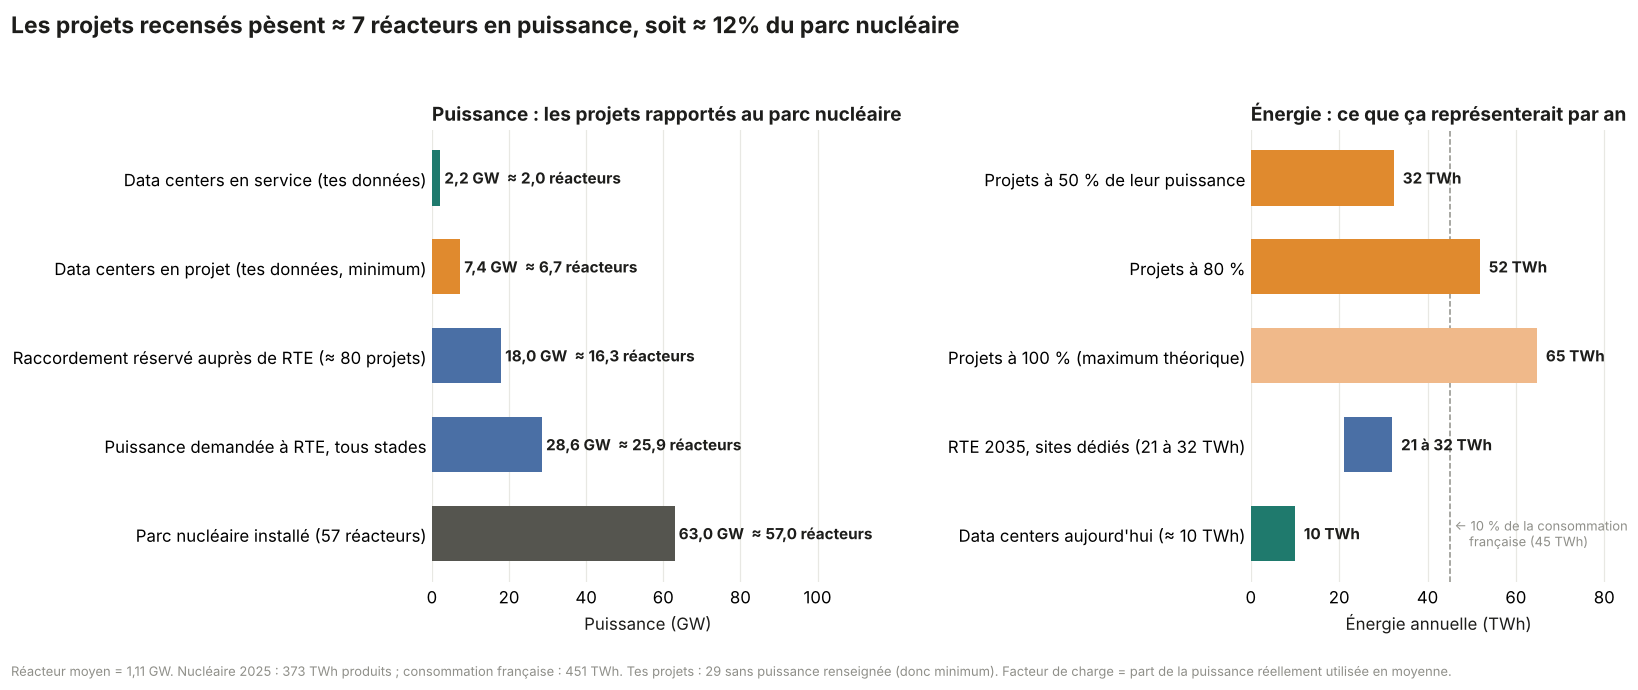

In [ ]:
GW_NUC, N_REAC = ext("Parc nucléaire, puissance installée"), 57
GW_REACTEUR = GW_NUC / N_REAC                                   # ≈ 1,1 GW
conso_fr, prod_nuc = ext("Consommation électrique France", 2025), ext("Production nucléaire")
rte_res, rte_dem = ext("Raccordement réservé data centers"), ext("Puissance demandée data centers")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})

# --- (a) Puissances en GW ---
lignes = [("Data centers en service (tes données)", GW_SERVICE, VERT),
          ("Data centers en projet (tes données, minimum)", GW_PROJET, ORANGE),
          ("Raccordement réservé auprès de RTE (≈ 80 projets)", rte_res, BLEU),
          ("Puissance demandée à RTE, tous stades", rte_dem, BLEU),
          ("Parc nucléaire installé (57 réacteurs)", GW_NUC, ANTHRA)]
y = np.arange(len(lignes))[::-1]
for yi, (lab, v, c) in zip(y, lignes):
    ax.barh(yi, v, color=c, height=.62, zorder=3)
    ax.text(v + 1, yi, f"{fmt(v, 1)} GW  ≈ {fmt(v / GW_REACTEUR, 1)} réacteurs", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y, [l[0] for l in lignes]); ax.set_xlim(0, 112)
ax.set_xlabel("Puissance (GW)"); ax.set_title("Puissance : les projets rapportés au parc nucléaire")
ax.xaxis.grid(True, color="#e8e8e3", zorder=0); ax.tick_params(length=0)
for s in ("left", "bottom"): ax.spines[s].set_visible(False)

# --- (b) Énergie annuelle en TWh ---
h = 8.76                                                         # milliers d'heures par an
twh = {lf: GW_PROJET * h * lf for lf in (.5, .8, 1.0)}
barres = [("Projets à 50 % de leur puissance", twh[.5], twh[.5], ORANGE),
          ("Projets à 80 %", twh[.8], twh[.8], ORANGE),
          ("Projets à 100 % (maximum théorique)", twh[1.0], twh[1.0], "#f0b98a"),
          ("RTE 2035, sites dédiés (21 à 32 TWh)", ext("Conso. data centers, sites dédiés", 2035), ext("Conso. data centers, sites dédiés", 2035, "valeur_haute"), BLEU),
          ("Data centers aujourd'hui (≈ 10 TWh)", 10, 10, VERT)]
y2 = np.arange(len(barres))[::-1]
for yi, (lab, lo, hi, c) in zip(y2, barres):
    ax2.barh(yi, hi if lo == hi else hi - lo, left=0 if lo == hi else lo, color=c, height=.62, zorder=3)
    ax2.text(hi + 2, yi, (f"{fmt(lo)} TWh" if lo == hi else f"{fmt(lo)} à {fmt(hi)} TWh"), va="center", fontsize=10, fontweight="bold")
ax2.set_yticks(y2, [b[0] for b in barres]); ax2.set_xlim(0, 85)
ax2.axvline(0.1 * conso_fr, color=GRIS, ls="--", lw=1, zorder=2)
ax2.text(0.1 * conso_fr + 1, y2[-1], f"← 10 % de la consommation\n    française ({fmt(0.1 * conso_fr)} TWh)", fontsize=8.5, color=GRIS, va="center")
ax2.set_xlabel("Énergie annuelle (TWh)"); ax2.set_title("Énergie : ce que ça représenterait par an")
ax2.xaxis.grid(True, color="#e8e8e3", zorder=0); ax2.tick_params(length=0)
for s in ("left", "bottom"): ax2.spines[s].set_visible(False)

fig.suptitle(f"Les projets recensés pèsent ≈ {fmt(GW_PROJET / GW_REACTEUR, 0)} réacteurs en puissance, "
             f"soit ≈ {GW_PROJET / GW_NUC:.0%} du parc nucléaire", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.text(.01, .005, f"Réacteur moyen = {fmt(GW_REACTEUR, 2)} GW. Nucléaire 2025 : {fmt(prod_nuc)} TWh produits ; consommation française : {fmt(conso_fr)} TWh. "
         f"Tes projets : {N_PROJ_SANS_MW} sans puissance renseignée (donc minimum). Facteur de charge = part de la puissance réellement utilisée en moyenne.",
         fontsize=8.5, color=GRIS, wrap=True)
plt.tight_layout(rect=(0, .04, 1, .94), w_pad=5)
plt.savefig("figures/7_equivalences.png", bbox_inches="tight", facecolor="white")
plt.show()

## 8. Part des data centers dans la consommation électrique française
Gauche : fourchettes RTE en TWh. Droite : « waffle » (1 carré = 1 % de la consommation nationale).

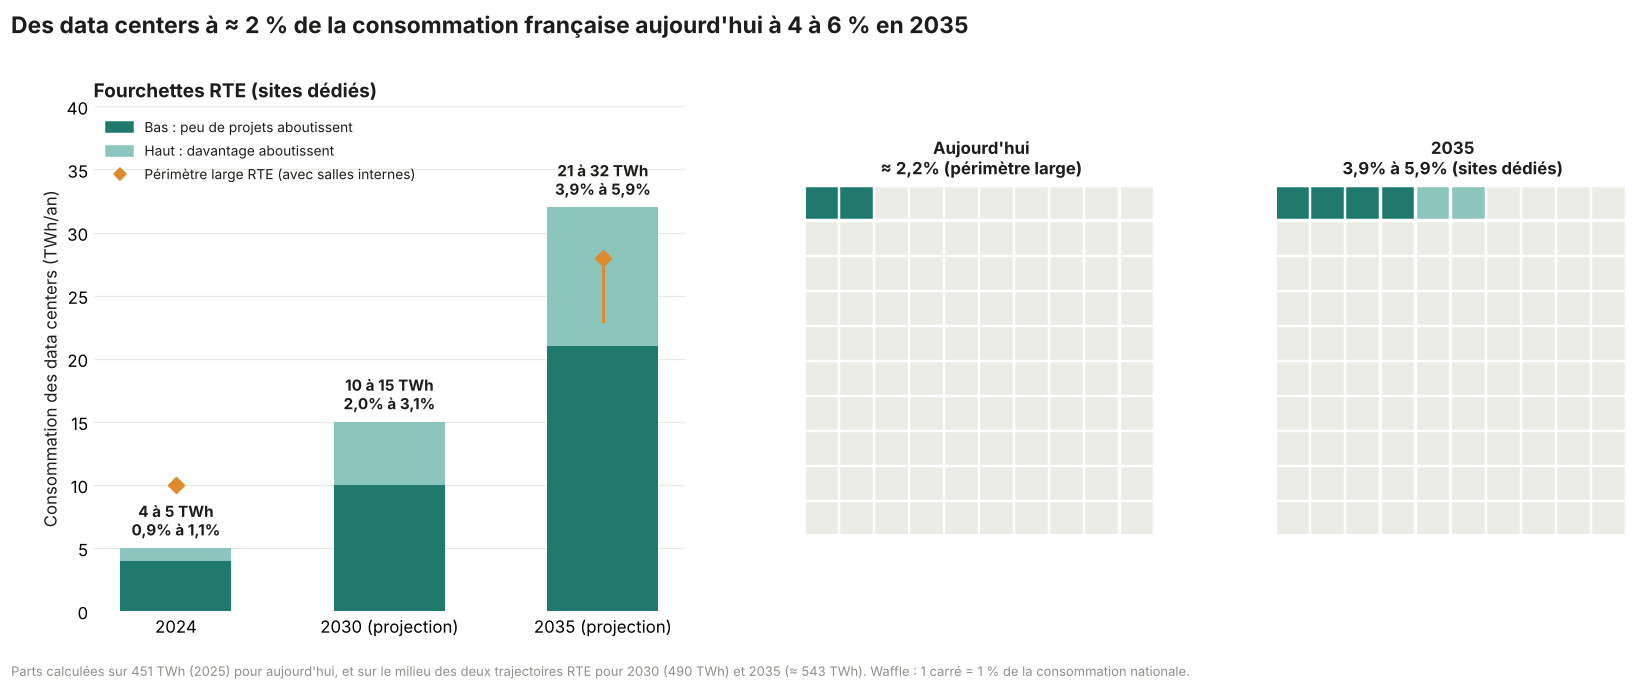

In [ ]:
conso = {2025: ext("Consommation électrique France", 2025)}
for a in (2030, 2035):                                          # milieu des deux trajectoires RTE
    conso[a] = (ext("Consommation électrique France", a) + ext("Consommation électrique France", a, "valeur_haute")) / 2
conso[2024] = conso[2025]                                       # base « aujourd'hui »

dc = {a: (ext("Conso. data centers, sites dédiés", a), ext("Conso. data centers, sites dédiés", a, "valeur_haute")) for a in (2024, 2030, 2035)}
part = {a: (dc[a][0] / conso[a], dc[a][1] / conso[a]) for a in dc}
part_large_auj = ext("Conso. data centers, périmètre large", 2026) / conso[2025]

fig = plt.figure(figsize=(15, 6.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.35, .8, .8], wspace=.28)
ax = fig.add_subplot(gs[0])
xs = np.arange(3)
for x, a in zip(xs, (2024, 2030, 2035)):
    lo, hi = dc[a]
    ax.bar(x, lo, color=VERT, width=.52, zorder=3)
    ax.bar(x, hi - lo, bottom=lo, color="#8cc5bc", width=.52, zorder=3)
    ax.text(x, hi + 1, f"{fmt(lo)} à {fmt(hi)} TWh\n{part[a][0]:.1%} à {part[a][1]:.1%}".replace(".", ","), ha="center", fontsize=10, fontweight="bold")
ax.scatter([0, 2], [ext("Conso. data centers, périmètre large", 2026), ext("Conso. data centers, périmètre large", 2035, "valeur_haute")],
           marker="D", color=ORANGE, zorder=4, s=55, label="Périmètre large RTE (avec salles internes)")
ax.plot([2, 2], [ext("Conso. data centers, périmètre large", 2035), ext("Conso. data centers, périmètre large", 2035, "valeur_haute")], color=ORANGE, lw=2, zorder=3)
ax.set_xticks(xs, ["2024", "2030 (projection)", "2035 (projection)"]); ax.set_ylim(0, 40)
ax.set_ylabel("Consommation des data centers (TWh/an)")
ax.legend(handles=[Patch(color=VERT, label="Bas : peu de projets aboutissent"), Patch(color="#8cc5bc", label="Haut : davantage aboutissent"),
                   plt.Line2D([], [], marker="D", color=ORANGE, ls="", label="Périmètre large RTE (avec salles internes)")],
          frameon=False, loc="upper left", fontsize=9)
ax.set_title("Fourchettes RTE (sites dédiés)"); ax.yaxis.grid(True, color="#e8e8e3", zorder=0)
for s in ("left", "bottom"): ax.spines[s].set_visible(False)
ax.tick_params(length=0)

def waffle(axw, bas, haut, titre):
    n_bas, n_haut = round(bas * 100), round(haut * 100)
    for i in range(100):
        r, c = divmod(i, 10)
        col = VERT if i < n_bas else ("#8cc5bc" if i < n_haut else "#ececE6")
        axw.add_patch(Rectangle((c, 9 - r), .88, .88, color=col))
    axw.set_xlim(0, 10); axw.set_ylim(0, 10); axw.set_aspect("equal"); axw.axis("off")
    axw.set_title(titre, fontsize=11, loc="center")
waffle(fig.add_subplot(gs[1]), part_large_auj, part_large_auj, f"Aujourd'hui\n≈ {part_large_auj:.1%} (périmètre large)".replace(".", ","))
waffle(fig.add_subplot(gs[2]), part[2035][0], part[2035][1], f"2035\n{part[2035][0]:.1%} à {part[2035][1]:.1%} (sites dédiés)".replace(".", ","))

fig.suptitle("Des data centers à ≈ 2 % de la consommation française aujourd'hui à 4 à 6 % en 2035", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.text(.01, .005, "Parts calculées sur 451 TWh (2025) pour aujourd'hui, et sur le milieu des deux trajectoires RTE pour 2030 (490 TWh) et 2035 (≈ 543 TWh). "
         "Waffle : 1 carré = 1 % de la consommation nationale.", fontsize=8.5, color=GRIS)
plt.subplots_adjust(top=.84, bottom=.1, left=.06, right=.99)
plt.savefig("figures/8_part_consommation.png", bbox_inches="tight", facecolor="white")
plt.show()

## 9. Intensité carbone : la même charge de calcul, selon le pays
On rejoue **le même calcul** dans chaque pays : l'entraînement de Llama 3.1 405B, puis 1 million de requêtes. Seul le mix électrique change.

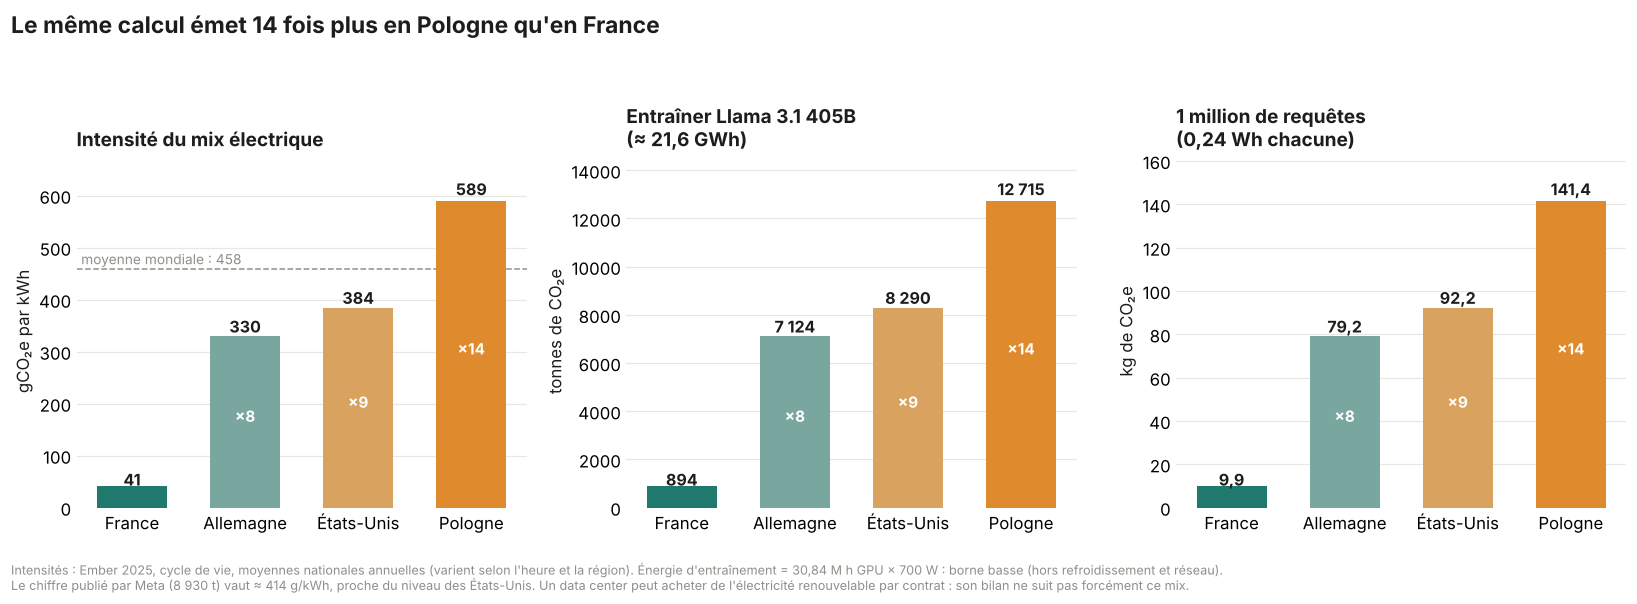

In [ ]:
pays = [("France", "Intensité carbone électricité : France"), ("Allemagne", "Intensité carbone électricité : Allemagne"),
        ("États-Unis", "Intensité carbone électricité : États-Unis"), ("Pologne", "Intensité carbone électricité : Pologne")]
noms = [p[0] for p in pays]; g_kwh = np.array([ext(p[1]) for p in pays]); monde = ext("Intensité carbone électricité : Monde")
cols = [VERT, "#7aa6a0", "#d9a35f", ORANGE]

# Même charge de calcul : énergie de l'entraînement de Llama 3.1 405B (heures GPU × 700 W) et 1 M de requêtes Gemini (0,24 Wh)
E_TRAIN_GWH = ext("Llama 3.1 405B, entraînement", unite="M heures GPU") * 0.700          # M h × kW → GWh   (≈ 21,6 GWh)
t_train = E_TRAIN_GWH * 1e6 * g_kwh / 1e6                                      # GWh→kWh × g/kWh → g → t
kg_1M = 0.24e-3 * 1e6 * g_kwh / 1e3                                            # 240 kWh × g/kWh → kg

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
def barres(ax, vals, titre, unite, dec=0, ref=None):
    b = ax.bar(noms, vals, color=cols, width=.62, zorder=3)
    for r, v in zip(b, vals):
        ax.text(r.get_x() + r.get_width() / 2, v * 1.02, f"{fmt(v, dec)}", ha="center", fontsize=10.5, fontweight="bold")
        if v != vals[0]:
            ax.text(r.get_x() + r.get_width() / 2, v * .5, f"×{v / vals[0]:.0f}", ha="center", color="white", fontsize=10, fontweight="bold")
    ax.set_title(titre); ax.set_ylabel(unite); ax.set_ylim(0, max(vals) * 1.15)
    ax.yaxis.grid(True, color="#e8e8e3", zorder=0); ax.tick_params(length=0)
    for s in ("left", "bottom"): ax.spines[s].set_visible(False)
barres(axes[0], g_kwh, "Intensité du mix électrique", "gCO₂e par kWh")
axes[0].axhline(monde, color=GRIS, ls="--", lw=1); axes[0].text(-0.45, monde + 10, f"moyenne mondiale : {fmt(monde)}", ha="left", fontsize=9, color=GRIS)
barres(axes[1], t_train, f"Entraîner Llama 3.1 405B\n(≈ {fmt(E_TRAIN_GWH, 1)} GWh)", "tonnes de CO₂e")
barres(axes[2], kg_1M, "1 million de requêtes\n(0,24 Wh chacune)", "kg de CO₂e", dec=1)

fig.suptitle("Le même calcul émet 14 fois plus en Pologne qu'en France", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.text(.01, .005, "Intensités : Ember 2025, cycle de vie, moyennes nationales annuelles (varient selon l'heure et la région). Énergie d'entraînement = 30,84 M h GPU × 700 W : borne basse "
         "(hors refroidissement et réseau).\nLe chiffre publié par Meta (8 930 t) vaut ≈ 414 g/kWh, proche du niveau des États-Unis. Un data center peut acheter de l'électricité renouvelable par contrat : son bilan ne suit pas forcément ce mix.",
         fontsize=8.3, color=GRIS)
plt.tight_layout(rect=(0, .07, 1, .93))
plt.savefig("figures/9_intensite_carbone.png", bbox_inches="tight", facecolor="white")
plt.show()

## 10. Cycle de vie : entraînement, fabrication, inférence
**Attention à ce que disent (et ne disent pas) les sources.** L'étude Mistral regroupe entraînement et 18 mois d'usage dans un même chiffre ; elle ne permet donc pas, seule, de montrer que « l'usage domine l'entraînement ». On présente donc : (a) la répartition publiée pour BLOOM et Mistral, et (b) un **calcul de seuil** : à partir de combien de requêtes l'inférence cumulée dépasse-t-elle l'entraînement ?

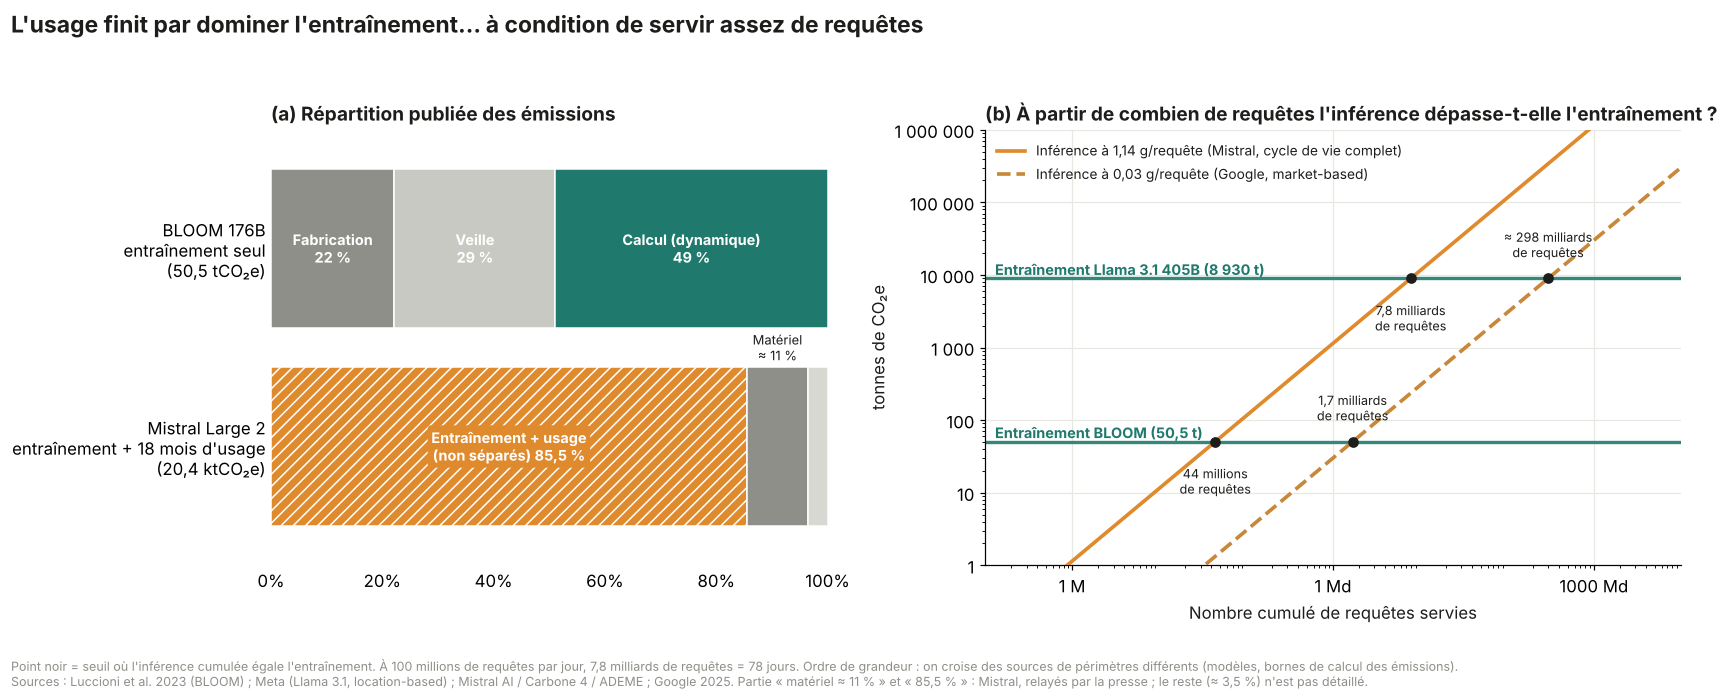

BLOOM           / Mistral : seuil =          44 millions de requêtes  ≈ 0,4 jours à 100 M requêtes/jour
BLOOM           / Google  : seuil =        1,7 milliards de requêtes  ≈ 16,8 jours à 100 M requêtes/jour
Llama 3.1 405B  / Mistral : seuil =        7,8 milliards de requêtes  ≈ 78,3 jours à 100 M requêtes/jour
Llama 3.1 405B  / Google  : seuil =      ≈ 298 milliards de requêtes  ≈ 2 976,7 jours à 100 M requêtes/jour


In [ ]:
T_BLOOM, T_LLAMA = ext("BLOOM 176B, entraînement"), ext("Llama 3.1 405B, entraînement", unite="tCO2e")        # tCO2e
E_GOOGLE, E_MISTRAL = ext("Gemini Apps, 1 prompt texte médian"), ext("Mistral Large 2, 1 réponse de 400 tokens")   # gCO2e / requête

def human(n):
    if n >= 1e12: return f"{n / 1e12:.0f} mille milliards"
    if n >= 1e10: return f"≈ {n / 1e9:.0f} milliards"
    if n >= 1e9:  return f"{n / 1e9:.1f} milliards".replace(".", ",")
    if n >= 1e6:  return f"{n / 1e6:.0f} millions"
    return f"{n:.0f}"

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.3), gridspec_kw={"width_ratios": [1, 1.25]})

# --- (a) Répartition publiée ---
bloom = [11.2 / 50.5 * 100, 14.6 / 50.5 * 100, 24.7 / 50.5 * 100]
ax.barh(1, bloom[0], color="#8f8f89", edgecolor="white", zorder=3)
ax.barh(1, bloom[1], left=bloom[0], color="#c9c9c4", edgecolor="white", zorder=3)
ax.barh(1, bloom[2], left=bloom[0] + bloom[1], color=VERT, edgecolor="white", zorder=3)
for x0, w, t in [(0, bloom[0], f"Fabrication\n{bloom[0]:.0f} %"), (bloom[0], bloom[1], f"Veille\n{bloom[1]:.0f} %"), (bloom[0] + bloom[1], bloom[2], f"Calcul (dynamique)\n{bloom[2]:.0f} %")]:
    ax.text(x0 + w / 2, 1, t, ha="center", va="center", color="white" if x0 != bloom[0] else "white", fontsize=9.5, fontweight="bold")
m_use, m_hw = ext("Mistral Large 2, part entraînement+usage"), 11.0
ax.barh(0, m_use, color=ORANGE, hatch="///", edgecolor="white", zorder=3)
ax.barh(0, m_hw, left=m_use, color="#8f8f89", edgecolor="white", zorder=3)
ax.barh(0, 100 - m_use - m_hw, left=m_use + m_hw, color="#d8d8d3", edgecolor="white", zorder=3)
ax.text(m_use / 2, 0, f"Entraînement + usage\n(non séparés) {m_use:.1f} %".replace(".", ","), ha="center", va="center", color="white", fontsize=9.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=.25", fc=ORANGE, ec="none"))
ax.text(m_use + m_hw / 2, 0.42, "Matériel\n≈ 11 %", ha="center", va="bottom", fontsize=8.5)
ax.set_yticks([1, 0], [f"BLOOM 176B\nentraînement seul\n({fmt(T_BLOOM, 1)} tCO₂e)", f"Mistral Large 2\nentraînement + 18 mois d'usage\n({fmt(ext('Mistral Large 2, ACV'), 1)} ktCO₂e)"])
ax.set_xlim(0, 100); ax.set_ylim(-.6, 1.6); ax.xaxis.set_major_formatter(mt.PercentFormatter()); ax.tick_params(length=0)
ax.set_title("(a) Répartition publiée des émissions"); 
for s in ("left", "bottom"): ax.spines[s].set_visible(False)

# --- (b) Seuil de basculement ---
N = np.logspace(5, 13, 200)
for e, c, ls, lab in [(E_MISTRAL, ORANGE, "-", f"Inférence à {fmt(E_MISTRAL, 2)} g/requête (Mistral, cycle de vie complet)"),
                      (E_GOOGLE, "#c9873a", "--", f"Inférence à {fmt(E_GOOGLE, 2)} g/requête (Google, market-based)")]:
    ax2.plot(N, e * N / 1e6, color=c, ls=ls, lw=2.4, label=lab, zorder=3)
for T, nom in [(T_BLOOM, f"Entraînement BLOOM ({fmt(T_BLOOM, 1)} t)"), (T_LLAMA, f"Entraînement Llama 3.1 405B ({fmt(T_LLAMA)} t)")]:
    ax2.axhline(T, color=VERT, lw=2.2, alpha=.9, zorder=2)
    ax2.text(1.3e5, T * 1.12, nom, color=VERT, fontsize=9.5, fontweight="bold")
    for e, c in [(E_MISTRAL, ORANGE), (E_GOOGLE, "#c9873a")]:
        n_star = T * 1e6 / e
        ax2.plot(n_star, T, "o", color=ENCRE, ms=6, zorder=5)
        ax2.annotate(f"{human(n_star)}\nde requêtes", (n_star, T), xytext=(0, -34 if e == E_MISTRAL else 14), textcoords="offset points",
                     ha="center", fontsize=8.3, color=ENCRE)
ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlim(1e5, 1e13); ax2.set_ylim(1, 1e6)
ax2.set_xlabel("Nombre cumulé de requêtes servies"); ax2.set_ylabel("tonnes de CO₂e")
ax2.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: {1e6: "1 M", 1e9: "1 Md", 1e12: "1000 Md"}.get(v, "")))
ax2.xaxis.set_major_locator(mt.FixedLocator([1e6, 1e9, 1e12])); ax2.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v)))
ax2.grid(True, color="#e8e8e3", which="major", zorder=0); ax2.legend(frameon=False, loc="upper left", fontsize=9)
ax2.set_title("(b) À partir de combien de requêtes l'inférence dépasse-t-elle l'entraînement ?")
for s in ("right", "top"): ax2.spines[s].set_visible(False)

fig.suptitle("L'usage finit par dominer l'entraînement… à condition de servir assez de requêtes", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.text(.01, .005, "Point noir = seuil où l'inférence cumulée égale l'entraînement. À 100 millions de requêtes par jour, 7,8 milliards de requêtes = 78 jours. "
         "Ordre de grandeur : on croise des sources de périmètres différents (modèles, bornes de calcul des émissions).\n"
         "Sources : Luccioni et al. 2023 (BLOOM) ; Meta (Llama 3.1, location-based) ; Mistral AI / Carbone 4 / ADEME ; Google 2025. "
         "Partie « matériel ≈ 11 % » et « 85,5 % » : Mistral, relayés par la presse ; le reste (≈ 3,5 %) n'est pas détaillé.", fontsize=8.2, color=GRIS)
plt.tight_layout(rect=(0, .07, 1, .94))
plt.savefig("figures/10_cycle_de_vie.png", bbox_inches="tight", facecolor="white")
plt.show()
for T, n in [(T_BLOOM, "BLOOM"), (T_LLAMA, "Llama 3.1 405B")]:
    for e, s_ in [(E_MISTRAL, "Mistral"), (E_GOOGLE, "Google")]:
        N0 = T * 1e6 / e
        print(f"{n:15s} / {s_:8s}: seuil = {human(N0):>20s} de requêtes  ≈ {fmt(N0 / 1e8, 1)} jours à 100 M requêtes/jour")

## 11. Carte des tensions locales : réseau électrique et eau
**Ce qui est mesuré** : la puissance de tes data centers par département (ton CSV). **Ce qui est qualitatif** : les zones que RTE désigne comme concentrant les demandes de raccordement (Île-de-France, Marseille, Hauts-de-France) et les zones industrialo-portuaires prioritaires du schéma décennal (Dunkerque, Le Havre, Fos-sur-Mer) ; leurs positions sont approximatives.

⚠️ La carte officielle « zones saturées » d'Enedis/RTE (2026) porte sur le raccordement de **production** (solaire, éolien), pas sur la consommation des data centers : ne la présente pas comme une carte de saturation « data centers ».

**Eau** : il n'existe pas de jeu ouvert simple. Pour ajouter une couche de stress hydrique, télécharge un export du *WRI Aqueduct Water Risk Atlas* en GeoJSON, puis renseigne `EAU_GEOJSON` ci-dessous.

In [ ]:
import folium
from branca.colormap import StepColormap

EAU_GEOJSON = None          # ex. "aqueduct_france.geojson"  (None = pas de couche eau)
EAU_CHAMP = "bws_label"     # nom du champ « stress hydrique » dans ton fichier (catégories ou valeur)

URL = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
geo = json.load(urllib.request.urlopen(URL))

def code_dep(r):
    if pd.isna(r.department): return ""
    c = str(int(r.department)).zfill(2)
    if c == "20" and pd.notna(r.city_code): return "2A" if int(r.city_code) < 20200 else "2B"
    return c
df["dep"] = df.apply(code_dep, axis=1)

# --- Puissance et nombre de sites par département ---
agg = df.pivot_table(index="dep", columns="statut", values="mw", aggfunc="sum", fill_value=0)
for c in ("En service", "En projet"):
    if c not in agg: agg[c] = 0
agg["total"] = agg["En service"] + agg["En projet"]
agg["n_sites"] = df.groupby("dep").size()
agg["n_sans_mw"] = df[df.mw.isna()].groupby("dep").size()
agg = agg.fillna(0)
hors = agg.loc[""] if "" in agg.index else None
if hors is not None:
    print(f"Attention : {int(hors['n_sites'])} sites ({hors['total']:.0f} MW) n'ont pas de département renseigné : "
          f"ils apparaissent comme points mais pas dans les couleurs par département.")

for f in geo["features"]:
    code = f["properties"]["code"]; r = agg.loc[code] if code in agg.index else None
    f["properties"].update(
        mw_service=float(r["En service"]) if r is not None else 0.0, mw_projet=float(r["En projet"]) if r is not None else 0.0,
        mw_total=float(r["total"]) if r is not None else 0.0, n_sites=int(r["n_sites"]) if r is not None else 0,
        n_sans_mw=int(r["n_sans_mw"]) if r is not None else 0)

BINS = [0, 1, 10, 50, 200, 1000, 10000]
cmap = StepColormap(["#f2f2ee", "#fde3b8", "#f8b968", "#e08a2e", "#b5601a", "#6b330c"], vmin=0, vmax=10000, index=BINS,
                    caption="Puissance cumulée par département (MW), sites avec puissance renseignée")

m = folium.Map(location=[46.6, 2.5], zoom_start=6, tiles=None)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles © Esri", name="Fond").add_to(m)
m.fit_bounds([[41.3, -5.2], [51.1, 9.6]])

def couche(champ, nom, defaut=False):
    folium.GeoJson(geo, name=nom, overlay=False, show=defaut,
        style_function=lambda f, c=champ: {"fillColor": cmap(max(f["properties"][c], 0.001)) if f["properties"][c] > 0 else "#f7f7f4",
                                           "fillOpacity": .85, "color": "#b5b5b5", "weight": .5},
        highlight_function=lambda f: {"weight": 2, "color": "#222"},
        tooltip=folium.GeoJsonTooltip(fields=["nom", "mw_service", "mw_projet", "n_sites", "n_sans_mw"],
            aliases=["Département", "En service (MW)", "En projet (MW)", "Sites", "dont sans puissance"], localize=True, sticky=True)).add_to(m)
couche("mw_total", "Puissance totale (service + projet)", True)
couche("mw_service", "Puissance en service")
couche("mw_projet", "Puissance en projet")
cmap.add_to(m)

# --- Data centers ---
pts = df.dropna(subset=["latitude", "longitude"])
pts = pts[pts.latitude.between(41, 51.5) & pts.longitude.between(-5.5, 9.8)]
fg = folium.FeatureGroup(name="Data centers", show=True)
for r in pts.itertuples():
    c = VERT if r.statut == "En service" else "#1d1d1b"
    folium.CircleMarker([r.latitude, r.longitude], radius=2.2 + (0 if pd.isna(r.mw) else r.mw) ** .5 / 3.2, color=c, weight=.8,
                        fill=True, fill_color=c, fill_opacity=.55,
                        tooltip=f"{r.name} · {'puissance non renseignée' if pd.isna(r.mw) else f'{r.mw:g} MW'} · {r.statut.lower()}").add_to(fg)
fg.add_to(m)

# --- Zones nommées par RTE (positions approximatives, qualitatif) ---
ZONES = [("Île-de-France", 48.85, 2.45, 45, "RTE : zone où se concentrent les demandes de raccordement ; ≈ 64 % de la consommation des data centers", "#b5601a"),
         ("Marseille – Fos", 43.40, 5.10, 28, "RTE : zone de concentration ; la CRE signale l'absence de capacité disponible à Plan de Campagne", "#b5601a"),
         ("Hauts-de-France (Dunkerque)", 51.00, 2.30, 30, "RTE : zone de concentration ; zone industrialo-portuaire prioritaire (P1) du schéma décennal", "#b5601a"),
         ("Le Havre", 49.49, 0.11, 22, "Zone P1 du schéma décennal de RTE (renforcement du réseau)", "#6b6b65")]
fz = folium.FeatureGroup(name="Zones citées par RTE (qualitatif, approximatif)", show=True)
for nom, lat, lon, km, txt, col in ZONES:
    folium.Circle([lat, lon], radius=km * 1000, color=col, weight=2.2, dash_array="6,6", fill=False, tooltip=f"<b>{nom}</b><br>{txt}").add_to(fz)
fz.add_to(m)

# --- Couche eau (optionnelle) ---
if EAU_GEOJSON and os.path.exists(EAU_GEOJSON):
    eau = json.load(open(EAU_GEOJSON, encoding="utf-8"))
    NIV = {"low": "#cfe3f0", "low-medium": "#a9cbe3", "medium-high": "#6fa6cf", "high": "#3a78b0", "extremely high": "#123e75"}
    def style_eau(f):
        v = f["properties"].get(EAU_CHAMP); k = str(v).strip().lower()
        return {"fillColor": NIV.get(k, "#9ab"), "fillOpacity": .45, "color": "#456", "weight": .3}
    folium.GeoJson(eau, name="Stress hydrique (fichier fourni)", style_function=style_eau, show=False,
                   tooltip=folium.GeoJsonTooltip(fields=[EAU_CHAMP], aliases=["Stress hydrique"])).add_to(m)
    print("Couche eau ajoutée.")
else:
    print("Pas de couche eau : renseigne EAU_GEOJSON pour l'ajouter (voir le texte au-dessus).")

folium.LayerControl(collapsed=False).add_to(m)
m.get_root().header.add_child(folium.Element("<style>.leaflet-control-layers{font:13px Arial}</style>"))
m.save("carte_tensions.html")
print("Départements les plus chargés :"); print(agg.sort_values("total", ascending=False)[["En service", "En projet", "total", "n_sites"]].head(6).round(0))
m

Attention : 10 sites (1105 MW) n'ont pas de département renseigné : ils apparaissent comme points mais pas dans les couleurs par département.
Pas de couche eau : renseigne EAU_GEOJSON pour l'ajouter (voir le texte au-dessus).


Départements les plus chargés :
statut  En service  En projet   total  n_sites
dep                                           
77           156.0     2105.0  2262.0       22
91           402.0      788.0  1190.0       55
59           128.0     1000.0  1128.0       39
              13.0     1092.0  1105.0       10
93           397.0      658.0  1056.0       32
36             0.0      500.0   500.0        1
